# Apex3D · 01c · Deep baselines: ResNet-50 and EfficientNetV2-S

**Owner:** Person A. The proposal (§13) trains ConvNeXt-Tiny as the main classifier, *with an EfficientNetV2-S and a ResNet-50 baseline*. This notebook trains both baselines with **the same split, crops, augmentation, two-stage schedule, early stopping and temperature scaling** as notebook 01. The only thing that changes is the backbone, so the comparison isolates the architecture.

Run notebook 01 first: it caches the crops and writes `results/split.json`. Results go to `results/baselines_metrics.json`, which the app reads, and nothing here is hardcoded.

In [1]:
import os, sys, json, time, random, platform
from pathlib import Path
REPO = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "notebooks" / "cls_lib.py").exists())
sys.path.insert(0, str(REPO / "notebooks"))
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import torch, torch.nn as nn, torch.nn.functional as F, timm
from torch.utils.data import DataLoader
from timm.optim import create_optimizer_v2
from timm.scheduler import CosineLRScheduler
import cls_lib as L

DATA_DIR  = Path(os.environ.get("APEX3D_DATA", REPO / "data" / "raw"))
CACHE_DIR = REPO / "data" / "crops"
CKPT_DIR  = REPO / "checkpoints"
RESULTS   = REPO / "results"
PLOTS     = RESULTS / "plots"
for d in (CKPT_DIR, PLOTS): d.mkdir(parents=True, exist_ok=True)

# Recipe: identical to notebook 01 (read from its metrics file, so the two cannot drift apart)
REF = json.loads((RESULTS / "classifier_metrics.json").read_text())
R = REF["training"]
IMG_SIZE, BATCH, EFFECTIVE_BATCH = REF["model"]["img_size"], R["batch"], R["effective_batch"]
HEAD_EPOCHS, FT_EPOCHS, PATIENCE = R["head_epochs"], R["max_ft_epochs"], 5
LR_HEAD, LR_FT, LAYER_DECAY, WEIGHT_DECAY, LABEL_SMOOTHING = R["lr_head"], R["lr_ft"], R["layer_decay"], R["weight_decay"], R["label_smoothing"]
WARMUP_EPOCHS, NUM_WORKERS, SEED = 1, 2, 42

MODELS = {
    "resnet50": "resnet50.a1_in1k",                           # timm ResNet-50 (Apache-2.0), ImageNet-1k
    "efficientnetv2_s": "tf_efficientnetv2_s.in21k_ft_in1k",  # EfficientNetV2-S (Apache-2.0), ImageNet-21k -> 1k
}
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print({"torch": torch.__version__, "timm": timm.__version__, "gpu": torch.cuda.get_device_name(0) if DEVICE == "cuda" else None})
print("recipe from notebook 01:", {k: R[k] for k in ("batch", "effective_batch", "lr_head", "lr_ft", "layer_decay", "weight_decay", "label_smoothing")})
NOTEBOOK_START = time.time()

{'torch': '2.11.0+cu128', 'timm': '1.0.31', 'gpu': 'NVIDIA GeForce RTX 3050 Laptop GPU'}
recipe from notebook 01: {'batch': 32, 'effective_batch': 64, 'lr_head': 0.001, 'lr_ft': 0.0003, 'layer_decay': 0.9, 'weight_decay': 0.05, 'label_smoothing': 0.1}


## Data: same split and cached crops as notebook 01

In [2]:
ROOT = L.find_stanford_root(DATA_DIR)
class_names = L.load_class_names(ROOT)
split = json.loads((RESULTS / "split.json").read_text())
train_all = {Path(r.path).name: r for r in L.load_split(ROOT, "train")}
test_recs = L.load_split(ROOT, "test")
def cached(rec): return str(CACHE_DIR / (Path(rec.path).parent.name + "_" + Path(rec.path).stem + ".jpg"))
train_recs = [train_all[f] for f in split["train"]]; val_recs = [train_all[f] for f in split["val"]]
tr_paths, va_paths, te_paths = [cached(r) for r in train_recs], [cached(r) for r in val_recs], [cached(r) for r in test_recs]
tr_y, va_y, te_y = [r.label for r in train_recs], [r.label for r in val_recs], [r.label for r in test_recs]
missing = [p for p in tr_paths + va_paths + te_paths if not Path(p).exists()]
assert not missing, f"{len(missing)} cached crops missing: run notebook 01 first"
print(len(tr_paths), "train /", len(va_paths), "val /", len(te_paths), "test")

def loader(paths, ys, tf, shuffle, bs=BATCH, persistent=False):
    return DataLoader(L.CropDataset(paths, ys, tf), batch_size=bs, shuffle=shuffle, num_workers=NUM_WORKERS,
                      pin_memory=True, persistent_workers=persistent, drop_last=shuffle)

6922 train / 1222 val / 8041 test


## Shared training code (same as notebook 01)

In [3]:
def topk_acc(logits, y, k): return (logits.topk(k, 1).indices == y[:, None]).any(1).float().mean().item()

@torch.no_grad()
def predict(model, dl):
    model.eval(); out, ys = [], []
    for x, y in dl:
        x = x.to(DEVICE, non_blocking=True).to(memory_format=torch.channels_last)
        with torch.autocast("cuda", dtype=torch.float16, enabled=DEVICE == "cuda"):
            out.append(model(x).float().cpu())
        ys.append(y)
    return torch.cat(out), torch.cat(ys)

def fit_temperature(logits, y):
    logT = torch.zeros(1, requires_grad=True)
    opt = torch.optim.LBFGS([logT], lr=0.1, max_iter=200)
    def closure():
        opt.zero_grad(); loss = F.cross_entropy(logits / logT.exp(), y); loss.backward(); return loss
    opt.step(closure)
    return logT.detach().exp().item()

def ece(probs, y, bins=15):
    conf, pred = probs.max(1); acc = (pred == y).float(); e = 0.0
    edges = torch.linspace(0, 1, bins + 1)
    for lo, hi in zip(edges[:-1], edges[1:]):
        m = (conf > lo) & (conf <= hi)
        if m.any(): e += m.float().mean().item() * abs(acc[m].mean().item() - conf[m].mean().item())
    return e

def bench(model, device, n=50):
    model = model.to(device).eval().to(memory_format=torch.contiguous_format)
    x = torch.randn(1, 3, IMG_SIZE, IMG_SIZE, device=device)
    with torch.no_grad():
        for _ in range(10): model(x)
        if device == "cuda": torch.cuda.synchronize()
        t0 = time.perf_counter()
        for _ in range(n): model(x)
        if device == "cuda": torch.cuda.synchronize()
    return (time.perf_counter() - t0) / n * 1000

def train_and_evaluate(key, arch):
    seed_everything(SEED)
    model = L.build_model(arch, 196, pretrained=True).to(DEVICE).to(memory_format=torch.channels_last)
    n_params = sum(p.numel() for p in model.parameters())
    # batch-size probe on the 4 GB GPU; gradient checkpointing only if batch 32 does not fit
    grad_ckpt = False
    if DEVICE == "cuda":
        model.train()
        try:
            torch.cuda.empty_cache(); torch.cuda.reset_peak_memory_stats()
            x = torch.randn(BATCH, 3, IMG_SIZE, IMG_SIZE, device=DEVICE).to(memory_format=torch.channels_last)
            with torch.autocast("cuda", dtype=torch.float16): model(x).float().mean().backward()
            peak = torch.cuda.max_memory_allocated() / 2**30
        except torch.cuda.OutOfMemoryError:
            model.zero_grad(set_to_none=True); torch.cuda.empty_cache()
            grad_ckpt = True; model.set_grad_checkpointing(True); peak = None
        model.zero_grad(set_to_none=True); x = None
    accum = max(1, EFFECTIVE_BATCH // BATCH)
    print(f"[{key}] {arch}: {n_params/1e6:.1f}M params | peak VRAM at batch {BATCH}: {peak if peak is None else round(peak, 2)} GiB | grad ckpt {grad_ckpt}")

    dl_train = loader(tr_paths, tr_y, L.train_transform(IMG_SIZE), True, persistent=True)
    dl_val = loader(va_paths, va_y, L.eval_transform(IMG_SIZE), False, bs=64, persistent=True)
    criterion = nn.CrossEntropyLoss(label_smoothing=LABEL_SMOOTHING)
    scaler = torch.amp.GradScaler("cuda", enabled=DEVICE == "cuda")
    history = []

    def run_epoch(opt, sched, epoch):
        model.train(); tot = correct = 0; loss_sum = 0.0; steps = len(dl_train) // accum
        opt.zero_grad(set_to_none=True)
        for i, (x, y) in enumerate(dl_train):
            x = x.to(DEVICE, non_blocking=True).to(memory_format=torch.channels_last); y = y.to(DEVICE, non_blocking=True)
            with torch.autocast("cuda", dtype=torch.float16, enabled=DEVICE == "cuda"):
                out = model(x); loss = criterion(out, y) / accum
            scaler.scale(loss).backward()
            if (i + 1) % accum == 0:
                scaler.unscale_(opt); nn.utils.clip_grad_norm_(model.parameters(), 1.0)
                scaler.step(opt); scaler.update(); opt.zero_grad(set_to_none=True)
                if sched is not None: sched.step_update(epoch * steps + (i + 1) // accum)
            loss_sum += loss.item() * accum * len(y); tot += len(y); correct += (out.argmax(1) == y).sum().item()
        return loss_sum / tot, correct / tot

    def log(stage, tl, ta, t0, lr):
        vlog, vy = predict(model, dl_val)
        history.append({"stage": stage, "epoch": len(history) + 1, "train_loss": tl, "train_acc": ta,
                        "val_loss": F.cross_entropy(vlog, vy).item(), "val_top1": topk_acc(vlog, vy, 1),
                        "val_top5": topk_acc(vlog, vy, 5), "lr": lr, "sec": time.time() - t0})
        print(f"[{key}]", {k: round(v, 4) if isinstance(v, float) else v for k, v in history[-1].items()}, flush=True)
        return history[-1]["val_top1"]

    # stage 1: head only
    for p in model.parameters(): p.requires_grad = False
    for p in model.get_classifier().parameters(): p.requires_grad = True
    opt = torch.optim.AdamW(model.get_classifier().parameters(), lr=LR_HEAD, weight_decay=WEIGHT_DECAY)
    t_start = time.time()
    for ep in range(HEAD_EPOCHS):
        t0 = time.time(); tl, ta = run_epoch(opt, None, ep); log(1, tl, ta, t0, LR_HEAD)

    # stage 2: full fine-tune, layer-wise LR decay, cosine, early stopping
    for p in model.parameters(): p.requires_grad = True
    opt = create_optimizer_v2(model, opt="adamw", lr=LR_FT, weight_decay=WEIGHT_DECAY, layer_decay=LAYER_DECAY)
    steps = len(dl_train) // accum
    sched = CosineLRScheduler(opt, t_initial=FT_EPOCHS * steps, lr_min=1e-6, warmup_t=WARMUP_EPOCHS * steps,
                              warmup_lr_init=1e-6, t_in_epochs=False)
    best_path = CKPT_DIR / f"baseline_{key}_best_state.pt"
    best, best_epoch, bad = -1.0, None, 0
    for ep in range(FT_EPOCHS):
        t0 = time.time(); tl, ta = run_epoch(opt, sched, ep)
        v1 = log(2, tl, ta, t0, max(g["lr"] for g in opt.param_groups))
        if v1 > best: best, best_epoch, bad = v1, history[-1]["epoch"], 0; torch.save(model.state_dict(), best_path)
        else:
            bad += 1
            if bad >= PATIENCE: print(f"[{key}] early stop"); break
    train_min = (time.time() - t_start) / 60
    model.load_state_dict(torch.load(best_path, map_location=DEVICE))
    if grad_ckpt: model.set_grad_checkpointing(False)

    # calibration on validation, then ONE test evaluation
    vlog, vy = predict(model, dl_val); T = fit_temperature(vlog, vy)
    dl_test = loader(te_paths, te_y, L.eval_transform(IMG_SIZE), False, bs=64)
    tlog, ty = predict(model, dl_test)
    tp = (tlog / T).softmax(1); pred = tp.argmax(1).numpy(); yt = ty.numpy()
    make = np.array([L.parse_class_name(n)["make"] for n in class_names])
    from sklearn.metrics import f1_score
    res = {
        "arch": arch, "params_m": n_params / 1e6, "img_size": IMG_SIZE, "grad_checkpointing": grad_ckpt,
        "peak_train_vram_gib_batch32": peak, "epochs_run": len(history), "best_epoch": best_epoch, "train_min": train_min,
        "val_top1": topk_acc(vlog, vy, 1), "val_top5": topk_acc(vlog, vy, 5), "temperature": T,
        "test_top1": topk_acc(tlog, ty, 1), "test_top5": topk_acc(tlog, ty, 5),
        "test_make_top1": float((make[pred] == make[yt]).mean()), "test_macro_f1": float(f1_score(yt, pred, average="macro")),
        "test_ece_calibrated": ece(tp, ty),
    }
    bundle = CKPT_DIR / f"baseline_{key}.pt"
    L.save_bundle(bundle, model, arch=arch, img_size=IMG_SIZE, class_names=class_names, temperature=T,
                  thresholds=REF["thresholds"], extra={"note": "baseline; thresholds copied from the ConvNeXt model, not tuned for this one"})
    res["checkpoint_mb"] = bundle.stat().st_size / 1e6
    if DEVICE == "cuda": res["gpu_fp32_ms"] = bench(model, "cuda")
    res["cpu_fp32_ms"] = bench(model, "cpu", n=20)
    pd.DataFrame(history).to_csv(RESULTS / f"baseline_{key}_history.csv", index=False)
    best_path.unlink()
    del model, opt, dl_train, dl_val, dl_test; torch.cuda.empty_cache()
    print(f"[{key}] TEST Top-1 {res['test_top1']:.4f} Top-5 {res['test_top5']:.4f} ({train_min:.0f} min)")
    return res, history

def seed_everything(seed):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)
torch.backends.cudnn.benchmark = True

## ResNet-50

In [4]:
RESULTS_BY_MODEL, HISTORIES = {}, {}
RESULTS_BY_MODEL["resnet50"], HISTORIES["resnet50"] = train_and_evaluate("resnet50", MODELS["resnet50"])

[resnet50] resnet50.a1_in1k: 23.9M params | peak VRAM at batch 32: 1.57 GiB | grad ckpt False


[resnet50] {'stage': 1, 'epoch': 1, 'train_loss': 5.184, 'train_acc': 0.0263, 'val_loss': 4.9246, 'val_top1': 0.0794, 'val_top5': 0.2406, 'lr': 0.001, 'sec': 167.3756}


[resnet50] {'stage': 1, 'epoch': 2, 'train_loss': 4.8646, 'train_acc': 0.1037, 'val_loss': 4.6689, 'val_top1': 0.1334, 'val_top5': 0.3134, 'lr': 0.001, 'sec': 135.17}


[resnet50] {'stage': 2, 'epoch': 3, 'train_loss': 4.5171, 'train_acc': 0.192, 'val_loss': 3.9412, 'val_top1': 0.1825, 'val_top5': 0.4444, 'lr': 0.0003, 'sec': 335.815}


[resnet50] {'stage': 2, 'epoch': 4, 'train_loss': 3.8126, 'train_acc': 0.2937, 'val_loss': 3.0815, 'val_top1': 0.3003, 'val_top5': 0.6293, 'lr': 0.0003, 'sec': 340.1314}


[resnet50] {'stage': 2, 'epoch': 5, 'train_loss': 3.2277, 'train_acc': 0.4316, 'val_loss': 2.5476, 'val_top1': 0.4149, 'val_top5': 0.7373, 'lr': 0.0003, 'sec': 336.4118}


... (24 outputs left out)

[resnet50] {'stage': 2, 'epoch': 30, 'train_loss': 1.2836, 'train_acc': 0.9537, 'val_loss': 0.9335, 'val_top1': 0.8273, 'val_top5': 0.955, 'lr': 0.0, 'sec': 339.0405}


[resnet50] {'stage': 2, 'epoch': 31, 'train_loss': 1.264, 'train_acc': 0.9572, 'val_loss': 0.9248, 'val_top1': 0.8298, 'val_top5': 0.9574, 'lr': 0.0, 'sec': 334.3716}


[resnet50] {'stage': 2, 'epoch': 32, 'train_loss': 1.2834, 'train_acc': 0.9567, 'val_loss': 0.8979, 'val_top1': 0.8298, 'val_top5': 0.9558, 'lr': 0.0, 'sec': 321.2386}


[resnet50] TEST Top-1 0.8158 Top-5 0.9570 (169 min)


## EfficientNetV2-S

In [5]:
RESULTS_BY_MODEL["efficientnetv2_s"], HISTORIES["efficientnetv2_s"] = train_and_evaluate("efficientnetv2_s", MODELS["efficientnetv2_s"])

[efficientnetv2_s] tf_efficientnetv2_s.in21k_ft_in1k: 20.4M params | peak VRAM at batch 32: 2.51 GiB | grad ckpt False


[efficientnetv2_s] {'stage': 1, 'epoch': 1, 'train_loss': 5.2475, 'train_acc': 0.0462, 'val_loss': 4.288, 'val_top1': 0.1162, 'val_top5': 0.3077, 'lr': 0.001, 'sec': 151.9924}


[efficientnetv2_s] {'stage': 1, 'epoch': 2, 'train_loss': 4.1593, 'train_acc': 0.1703, 'val_loss': 3.7564, 'val_top1': 0.2079, 'val_top5': 0.4501, 'lr': 0.001, 'sec': 121.8138}


[efficientnetv2_s] {'stage': 2, 'epoch': 3, 'train_loss': 3.4535, 'train_acc': 0.3244, 'val_loss': 2.6547, 'val_top1': 0.3903, 'val_top5': 0.6612, 'lr': 0.0003, 'sec': 321.1019}


[efficientnetv2_s] {'stage': 2, 'epoch': 4, 'train_loss': 2.6068, 'train_acc': 0.5343, 'val_loss': 1.8108, 'val_top1': 0.5638, 'val_top5': 0.8257, 'lr': 0.0003, 'sec': 325.776}


[efficientnetv2_s] {'stage': 2, 'epoch': 5, 'train_loss': 2.0191, 'train_acc': 0.714, 'val_loss': 1.3748, 'val_top1': 0.6628, 'val_top5': 0.901, 'lr': 0.0003, 'sec': 312.1641}


... (24 outputs left out)

[efficientnetv2_s] {'stage': 2, 'epoch': 30, 'train_loss': 0.9754, 'train_acc': 0.9957, 'val_loss': 0.9003, 'val_top1': 0.865, 'val_top5': 0.9681, 'lr': 0.0, 'sec': 343.1713}


[efficientnetv2_s] {'stage': 2, 'epoch': 31, 'train_loss': 0.9768, 'train_acc': 0.9954, 'val_loss': 0.8908, 'val_top1': 0.8625, 'val_top5': 0.9697, 'lr': 0.0, 'sec': 361.7951}


[efficientnetv2_s] {'stage': 2, 'epoch': 32, 'train_loss': 0.9767, 'train_acc': 0.9959, 'val_loss': 0.8854, 'val_top1': 0.865, 'val_top5': 0.9714, 'lr': 0.0, 'sec': 361.4169}


[efficientnetv2_s] TEST Top-1 0.8713 Top-5 0.9697 (161 min)


## Comparison with ConvNeXt-Tiny (notebook 01)

Every number below comes from the same test set (8,041 images, ground-truth crops). The ConvNeXt row is read from `results/classifier_metrics.json`.
Latency is batch 1 at 224 px in PyTorch FP32. CPU numbers vary by a few ms between runs.

,arch,params_m,checkpoint_mb,val_top1,test_top1,test_top5,test_make_top1,test_macro_f1,test_ece_calibrated,gpu_fp32_ms,cpu_fp32_ms,epochs_run,best_epoch
convnext_tiny (main),convnext_tiny.fb_in22k_ft_in1k,27.970852,111.949663,0.922259,0.922025,0.984206,0.971521,0.920765,0.024039,5.240606,56.28879,32,28
resnet50,resnet50.a1_in1k,23.909636,95.957883,0.835516,0.815819,0.956971,0.89566,0.814882,0.011413,4.463388,53.703435,32,28
efficientnetv2_s,tf_efficientnetv2_s.in21k_ft_in1k,20.428564,82.587403,0.864975,0.871285,0.969656,0.937073,0.870129,0.024352,11.568242,63.72068,32,30


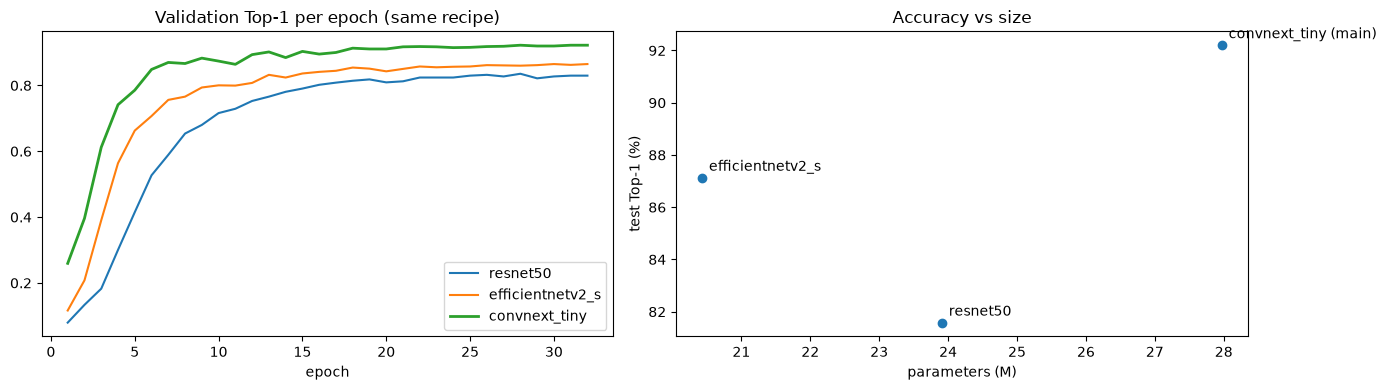

best on VALIDATION: convnext_tiny (main) (the app keeps whichever model validation prefers; test is reported only)
saved results/baselines_metrics.json


In [6]:
ref = {"arch": REF["model"]["arch"], "params_m": REF["model"]["params_m"], "checkpoint_mb": REF["model"]["checkpoint_mb"],
       "epochs_run": REF["training"]["epochs_run"], "best_epoch": REF["training"]["best_epoch"],
       "val_top1": REF["validation"]["top1"], "val_top5": REF["validation"]["top5"], "temperature": REF["calibration"]["temperature"],
       "test_top1": REF["test"]["top1"], "test_top5": REF["test"]["top5"], "test_make_top1": REF["test"]["make_top1"],
       "test_macro_f1": REF["test"]["macro_f1"], "test_ece_calibrated": REF["test"]["ece_calibrated"],
       "gpu_fp32_ms": REF["speed_ms"].get("gpu_fp32_ms"), "cpu_fp32_ms": REF["speed_ms"]["cpu_fp32_ms"]}
table = pd.DataFrame({"convnext_tiny (main)": ref, **RESULTS_BY_MODEL}).T
cols = ["arch", "params_m", "checkpoint_mb", "val_top1", "test_top1", "test_top5", "test_make_top1", "test_macro_f1", "test_ece_calibrated", "gpu_fp32_ms", "cpu_fp32_ms", "epochs_run", "best_epoch"]
display(table[cols])

fig, ax = plt.subplots(1, 2, figsize=(14, 4))
for key, h in HISTORIES.items():
    h = pd.DataFrame(h); ax[0].plot(h.epoch, h.val_top1, label=key)
h0 = pd.read_csv(RESULTS / "classifier_history.csv"); ax[0].plot(h0.epoch, h0.val_top1, label="convnext_tiny", lw=2)
ax[0].set_title("Validation Top-1 per epoch (same recipe)"); ax[0].set_xlabel("epoch"); ax[0].legend()
names = list(table.index); acc = table["test_top1"].astype(float).values; size = table["params_m"].astype(float).values
ax[1].scatter(size, acc * 100)
for n, s, a in zip(names, size, acc): ax[1].annotate(n, (s, a * 100), textcoords="offset points", xytext=(5, 5))
ax[1].set_xlabel("parameters (M)"); ax[1].set_ylabel("test Top-1 (%)"); ax[1].set_title("Accuracy vs size")
plt.tight_layout(); plt.savefig(PLOTS / "baselines_comparison.png", dpi=110); plt.show()

best_key = table["val_top1"].astype(float).idxmax()
print("best on VALIDATION:", best_key, "(the app keeps whichever model validation prefers; test is reported only)")
out = {"generated_by": "notebooks/01c_baseline_models.ipynb", "generated_at": time.strftime("%Y-%m-%d %H:%M:%S"),
       "recipe": "identical to notebook 01 (split, crops, augmentation, two-stage schedule, early stopping, temperature scaling)",
       "models": {"convnext_tiny": ref, **RESULTS_BY_MODEL}, "best_on_validation": best_key,
       "notebook_runtime_min": (time.time() - NOTEBOOK_START) / 60}
(RESULTS / "baselines_metrics.json").write_text(json.dumps(out, indent=2, default=float))
print("saved results/baselines_metrics.json")